# Supplementary Fig. S32: SAMap pseudotime transferred from mouse to human

The composite: the seven panels of the SAMap run, placed on the figure's 12-column grid (180 mm wide) with their
letters, written as PNG (300 and 600 dpi) and SVG (each panel's SVG nested in place, text kept as text), plus a
provenance record that merges the panels' own.

| panel | shows | drawn by |
|---|---|---|
| A | mouse pseudotime on the joint SAMap UMAP | `samap/notebooks/5_figures/sfig_samap_a_umap_mouse_pseudotime.ipynb` |
| B | pseudotime transferred onto the human nuclei | `..._b_umap_transferred_pseudotime.ipynb` |
| C | human pseudotime | `..._c_umap_human_pseudotime.ipynb` |
| D | cross-species edge weight by target compartment | `..._d_edge_share.ipynb` |
| E | transferred against human pseudotime, by compartment | `..._e_transferred_vs_human.ipynb` |
| F | transferred pseudotime on the human sections, observed and shuffled | `..._f_sections_shuffled.ipynb` |
| G | observed statistics against 1,000 shuffles of each design | `..._g_permutation_statistics.ipynb` |

This notebook reads only the three final objects: the SAMap object (joint UMAP, graph, cell types, transferred
pseudotime) and the two fibroblast/decidual objects (each species' pseudotime; the human section coordinates). From
them it computes the tables the panels read, with the pipeline's step-4 notebook (`samap/notebooks/4_statistics.ipynb`;
the 1,000 shuffles of each design are seeded), into `OUT/4_statistics/`. It then draws the panels by running the
pipeline's panel notebooks (`samap/notebooks/5_figures/sfig_samap_{a..g}_*.ipynb`, the same ones step 5 of the
pipeline runs) on those tables, into `OUT/panels/`, and composes them. The layout (grid, row heights,
panel spans) is the one the pipeline's `sfig_samap_style.py` holds; it is repeated here so the notebook stands alone.

Outputs, in `OUT`: `S32_samap_{DATE}.png`, `S32_samap_{DATE}_600dpi.png`, `S32_samap_{DATE}.svg`,
`S32_samap_{DATE}.provenance.json`. Nothing is overwritten: the notebook stops if an output exists.

In [1]:
# Parameters (papermill -p NAME VALUE overrides them)
OUT = "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_s32_v6"  # a new folder, outside the repository
D = "/n/lab_storage/eddy_lab/Lab/mckinley/data"  # the final objects; nothing else is read
SAMAP_FINAL = f"{D}/20261113_samap_final_ensembl_ids_pseudotime.h5ad"  # joint UMAP, graph, transferred pseudotime
HUMAN_H5AD = f"{D}/20261113_Human_only_eFib_dec_final_nick_v2.h5ad"  # human pseudotime and section coordinates
MOUSE_H5AD = f"{D}/20261113_mouse_only_eFib_dec_final_nick_v2.h5ad"  # mouse pseudotime
X_COLUMN = "x_um_dbscan"  # the human object's section coordinates
Y_COLUMN = "y_um_dbscan"
DATE = "20261113"  # goes into the file names
LETTER_FONT = ""  # path of a bold .ttf/.ttc for the PNG letters; "" picks the panels' font, else DejaVu Sans Bold


In [2]:
import datetime
import hashlib
import json
import os
import platform
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.font_manager as fm
from IPython.display import Image as ShowImage, display
from PIL import Image, ImageDraw, ImageFont

assert OUT, "set OUT, the folder for this figure"
OUT = Path(OUT).resolve()  # absolute: the panel notebooks run from their own folder and must find it
REPOSITORY = Path.cwd().resolve().parent  # this notebook runs from figures/
assert "xmens_figures" not in OUT.parts, "write to OUT; copy the checked figure into xmens_figures by hand"
assert REPOSITORY not in OUT.parents, f"OUT must be outside the repository ({REPOSITORY}), e.g. on netscratch"
OUT.mkdir(parents=True, exist_ok=True)
STEM = f"S32_samap_{DATE}"
outputs = {"png": OUT / f"{STEM}.png", "png_600dpi": OUT / f"{STEM}_600dpi.png", "svg": OUT / f"{STEM}.svg"}
sidecar = OUT / f"{STEM}.provenance.json"
existing = [str(p) for p in [*outputs.values(), sidecar] if p.exists()]
assert not existing, f"refusing to overwrite {existing}; change OUT or DATE"

# Everything is computed here from the three final objects, by the pipeline's own notebooks:
#   1. samap/notebooks/4_statistics.ipynb writes the tables the panels read (per-nucleus tables, edge shares, the
#      1,000 seeded shuffles of each design) into OUT/4_statistics/;
#   2. the seven panel notebooks (samap/notebooks/5_figures/) draw from those tables into OUT/panels/, each with its
#      SVG/PNG and a provenance JSON.
OBJECTS = {"samap_final": Path(SAMAP_FINAL), "human": Path(HUMAN_H5AD), "mouse": Path(MOUSE_H5AD)}
not_found = [str(path) for path in OBJECTS.values() if not path.is_file()]
assert not not_found, f"final objects not found: {not_found}"
SAMAP = REPOSITORY / "samap"
STATISTICS = SAMAP / "notebooks" / "4_statistics.ipynb"
PANEL_NOTEBOOKS = SAMAP / "notebooks" / "5_figures"
TABLES = OUT / "4_statistics"
PANELS = OUT / "panels"
assert STATISTICS.is_file() and PANEL_NOTEBOOKS.is_dir(), \
    f"{SAMAP / 'notebooks'} not found; run this notebook from the repository's figures/ folder"
assert not TABLES.exists(), f"{TABLES} exists; use a new OUT"
os.environ["JUPYTER_PATH"] = str(SAMAP / "jupyter")  # the pipeline's rsc kernel
import papermill as pm  # noqa: E402  (after JUPYTER_PATH, so the kernel is found)

(OUT / "notebooks").mkdir(parents=True, exist_ok=True)
pm.execute_notebook(str(STATISTICS), str(OUT / "notebooks" / "4_statistics.ipynb"),
                    parameters={"OUT": str(OUT), "SAMAP_FINAL": str(OBJECTS["samap_final"]),
                                "HUMAN_H5AD": str(OBJECTS["human"]), "MOUSE_H5AD": str(OBJECTS["mouse"]),
                                "X_COLUMN": X_COLUMN, "Y_COLUMN": Y_COLUMN},
                    kernel_name="rsc", cwd=str(STATISTICS.parent), progress_bar=False)
print(f"computed the tables from the final objects: {sorted(p.name for p in TABLES.iterdir())}")

joint = {"JOINT": TABLES / "tables/joint.parquet", "MOUSE_CELLS": TABLES / "tables/mouse_cells.csv",
         "HUMAN_CELLS": TABLES / "tables/human_cells.csv"}
PANEL_INPUTS = {
    "sfig_samap_a_umap_mouse_pseudotime": joint,
    "sfig_samap_b_umap_transferred_pseudotime": joint,
    "sfig_samap_c_umap_human_pseudotime": joint,
    "sfig_samap_d_edge_share": {"EDGE_SHARE": TABLES / "edge_share/samap_compartment_edge_share.csv"},
    "sfig_samap_e_transferred_vs_human": {"HUMAN_CELLS": TABLES / "tables/human_cells.csv"},
    "sfig_samap_f_sections_shuffled": {"HUMAN_CELLS": TABLES / "tables/human_cells.csv",
                                       "EXAMPLE_TRANSFERS": TABLES / "ptnull/example_transfers.csv"},
    "sfig_samap_g_permutation_statistics": {"NULL_REPLICATES": TABLES / "ptnull/null_replicates.csv",
                                            "EXAMPLE_TRANSFERS": TABLES / "ptnull/example_transfers.csv",
                                            "HUMAN_CELLS": TABLES / "tables/human_cells.csv"},
}
for name, inputs in PANEL_INPUTS.items():
    notebook = PANEL_NOTEBOOKS / f"{name}.ipynb"
    executed = OUT / "notebooks" / f"{name}.ipynb"
    executed.parent.mkdir(parents=True, exist_ok=True)
    parameters = {"REPO": str(SAMAP), "NOTEBOOK": str(notebook), "OUT": str(PANELS), "FORCE": True,
                  **{k: str(v) for k, v in inputs.items()}}
    pm.execute_notebook(str(notebook), str(executed), parameters=parameters, kernel_name="rsc",
                        cwd=str(PANEL_NOTEBOOKS), progress_bar=False)
    print(f"drew panel {name[11]}: {name}")


def sha256(path, block=1 << 24):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while chunk := handle.read(block):
            digest.update(chunk)
    return digest.hexdigest()

computed the tables from the final objects: ['alignment_scores.csv', 'edge_share', 'graph_block', 'label_agreement.csv', 'ptnull', 'statistics.json', 'tables']
drew panel a: sfig_samap_a_umap_mouse_pseudotime
drew panel b: sfig_samap_b_umap_transferred_pseudotime
drew panel c: sfig_samap_c_umap_human_pseudotime
drew panel d: sfig_samap_d_edge_share
drew panel e: sfig_samap_e_transferred_vs_human
drew panel f: sfig_samap_f_sections_shuffled
drew panel g: sfig_samap_g_permutation_statistics


## The grid

In [3]:
# 180 mm wide, 12 columns, 4 mm gutters; every panel spans whole columns of one row. As in sfig_samap_style.py.
DPI = 300
GUTTER_MM = 4
WIDTH_MM = 180
NCOL = 12
ROW_HEIGHTS_MM = [60, 55, 84]
PANEL_SPECS = {
    "a": {"row": 0, "col": 0, "colspan": 4},
    "b": {"row": 0, "col": 4, "colspan": 4},
    "c": {"row": 0, "col": 8, "colspan": 4},
    "d": {"row": 1, "col": 0, "colspan": 4},
    "e": {"row": 1, "col": 4, "colspan": 8},
    "f": {"row": 2, "col": 0, "colspan": 7},
    "g": {"row": 2, "col": 7, "colspan": 5},
}
LETTERS = list(PANEL_SPECS)
LETTER_PT = 11
LETTER_INSET_MM = (1.5, 1.0)  # letters in from the panel's top-left corner; every panel title leaves room
SVG_LETTER_FONTS = "Helvetica Neue, Helvetica, Arial, sans-serif"


def grid_geometry(dpi=DPI):
    """Figure width, column width, gutter, row heights and row tops, in whole pixels at dpi."""
    px_per_mm = dpi / 25.4
    width, gutter = int(WIDTH_MM * px_per_mm), int(GUTTER_MM * px_per_mm)
    col_width = (width - gutter * (NCOL - 1)) // NCOL
    row_heights = [int(h * px_per_mm) for h in ROW_HEIGHTS_MM]
    row_tops = [sum(row_heights[:i]) + gutter * i for i in range(len(row_heights))]
    return {"width": width, "col_width": col_width, "gutter": gutter, "row_heights": row_heights,
            "row_tops": row_tops, "height": row_tops[-1] + row_heights[-1]}


def panel_size_px(letter, dpi=DPI):
    grid, spec = grid_geometry(dpi), PANEL_SPECS[letter]
    width = grid["col_width"] * spec["colspan"] + grid["gutter"] * (spec["colspan"] - 1)
    return width, grid["row_heights"][spec["row"]]


def panel_origin_px(letter, dpi=DPI):
    grid, spec = grid_geometry(dpi), PANEL_SPECS[letter]
    return spec["col"] * (grid["col_width"] + grid["gutter"]), grid["row_tops"][spec["row"]]


def panel_files(letter):
    stem = PANELS / f"sfig_samap_panel_{letter}"
    return {"png": Path(f"{stem}.png"), "png_600dpi": Path(f"{stem}_600dpi.png"), "svg": Path(f"{stem}.svg"),
            "provenance": Path(f"{stem}.provenance.json")}

## Assembly

In [4]:
def bold_face(family):
    """(path, face index) of the bold face of family for the PIL-drawn letters; DejaVu Sans Bold if none."""
    if LETTER_FONT:
        return LETTER_FONT, 0
    for entry in fm.fontManager.ttflist:
        if entry.name != family or entry.weight not in (700, "bold") or entry.style != "normal":
            continue
        if not entry.fname.lower().endswith(".ttc"):
            return entry.fname, 0
        for index in range(32):  # a .ttc holds several faces; the first whose style name is Bold
            try:
                face = ImageFont.truetype(entry.fname, 20, index=index)
            except OSError:
                break
            if face.getname()[1] == "Bold":
                return entry.fname, index
    return os.path.join(mpl.get_data_path(), "fonts", "ttf", "DejaVuSans-Bold.ttf"), 0


def compose_png(key, out_path, dpi, letter_font):
    """Paste each panel PNG at its grid position on a white page and draw its letter; returns the page size."""
    grid = grid_geometry(dpi)
    page = Image.new("RGB", (grid["width"], grid["height"]), "white")
    draw = ImageDraw.Draw(page)
    font = ImageFont.truetype(letter_font[0], int(LETTER_PT / 72 * dpi), index=letter_font[1])
    for letter in LETTERS:
        width, height = panel_size_px(letter, dpi)
        x, y = panel_origin_px(letter, dpi)
        panel = Image.open(panel_files(letter)[key]).convert("RGBA")
        if panel.size != (width, height):  # whole-pixel grids: a 600-dpi panel can be a pixel off twice 300 dpi
            panel = panel.resize((width, height))
        page.paste(panel, (x, y), panel)
        inset_x, inset_y = (int(mm / 25.4 * dpi) for mm in LETTER_INSET_MM)
        draw.text((x + inset_x, y + inset_y), letter.upper(), fill="black", font=font)
    page.save(out_path)
    return grid["width"], grid["height"]


def compose_svg(out_path):
    """Nest each panel SVG at its grid position; ids get the panel letter as prefix so panels cannot collide."""
    pt = 72 / DPI  # the grid is in 300-dpi pixels
    grid = grid_geometry()
    page_w, page_h = grid["width"] * pt, grid["height"] * pt
    parts = [f'<?xml version="1.0" encoding="utf-8"?>\n<svg xmlns="http://www.w3.org/2000/svg" '
             f'xmlns:xlink="http://www.w3.org/1999/xlink" width="{page_w:.2f}pt" height="{page_h:.2f}pt" '
             f'viewBox="0 0 {page_w:.2f} {page_h:.2f}">\n<rect width="100%" height="100%" fill="white"/>']
    for letter in LETTERS:
        body = panel_files(letter)["svg"].read_text()
        body = re.sub(r"<\?xml[^>]*\?>|<!DOCTYPE[^>]*>", "", body).strip()
        body = re.sub(r'id="([^"]+)"', rf'id="{letter}_\1"', body)
        body = re.sub(r'(xlink:href|href)="#([^"]+)"', rf'\1="#{letter}_\2"', body)
        body = re.sub(r"url\(#([^)]+)\)", rf"url(#{letter}_\1)", body)
        width = float(re.search(r'<svg[^>]*\swidth="([\d.]+)pt"', body).group(1))
        height = float(re.search(r'<svg[^>]*\sheight="([\d.]+)pt"', body).group(1))
        x, y = (value * pt for value in panel_origin_px(letter))
        nested = (f'<svg x="{x:.3f}" y="{y:.3f}" width="{width:.3f}" height="{height:.3f}" '
                  f'viewBox="0 0 {width} {height}" xmlns="http://www.w3.org/2000/svg" '
                  f'xmlns:xlink="http://www.w3.org/1999/xlink">')
        body = re.sub(r"<svg\b[^>]*>", nested, body, count=1)
        parts.append(f'<g id="panel_{letter}">{body}</g>')
        # Same place as the PNG letters: 1.5 mm in, baseline one cap height below 1 mm.
        parts.append(f'<text x="{x + 4.25:.2f}" y="{y + 11.41:.2f}" font-family="{SVG_LETTER_FONTS}" '
                     f'font-weight="bold" font-size="{LETTER_PT}" fill="black">{letter.upper()}</text>')
    parts.append("</svg>\n")
    out_path.write_text("\n".join(parts))

## Run

panel font 'Nimbus Sans'; letters drawn with ('/usr/share/fonts/urw-base35/NimbusSans-Bold.otf', 0)
wrote ['S32_samap_20261113.png', 'S32_samap_20261113_600dpi.png', 'S32_samap_20261113.svg']: 2125 x 2443 px = 180 x 207 mm


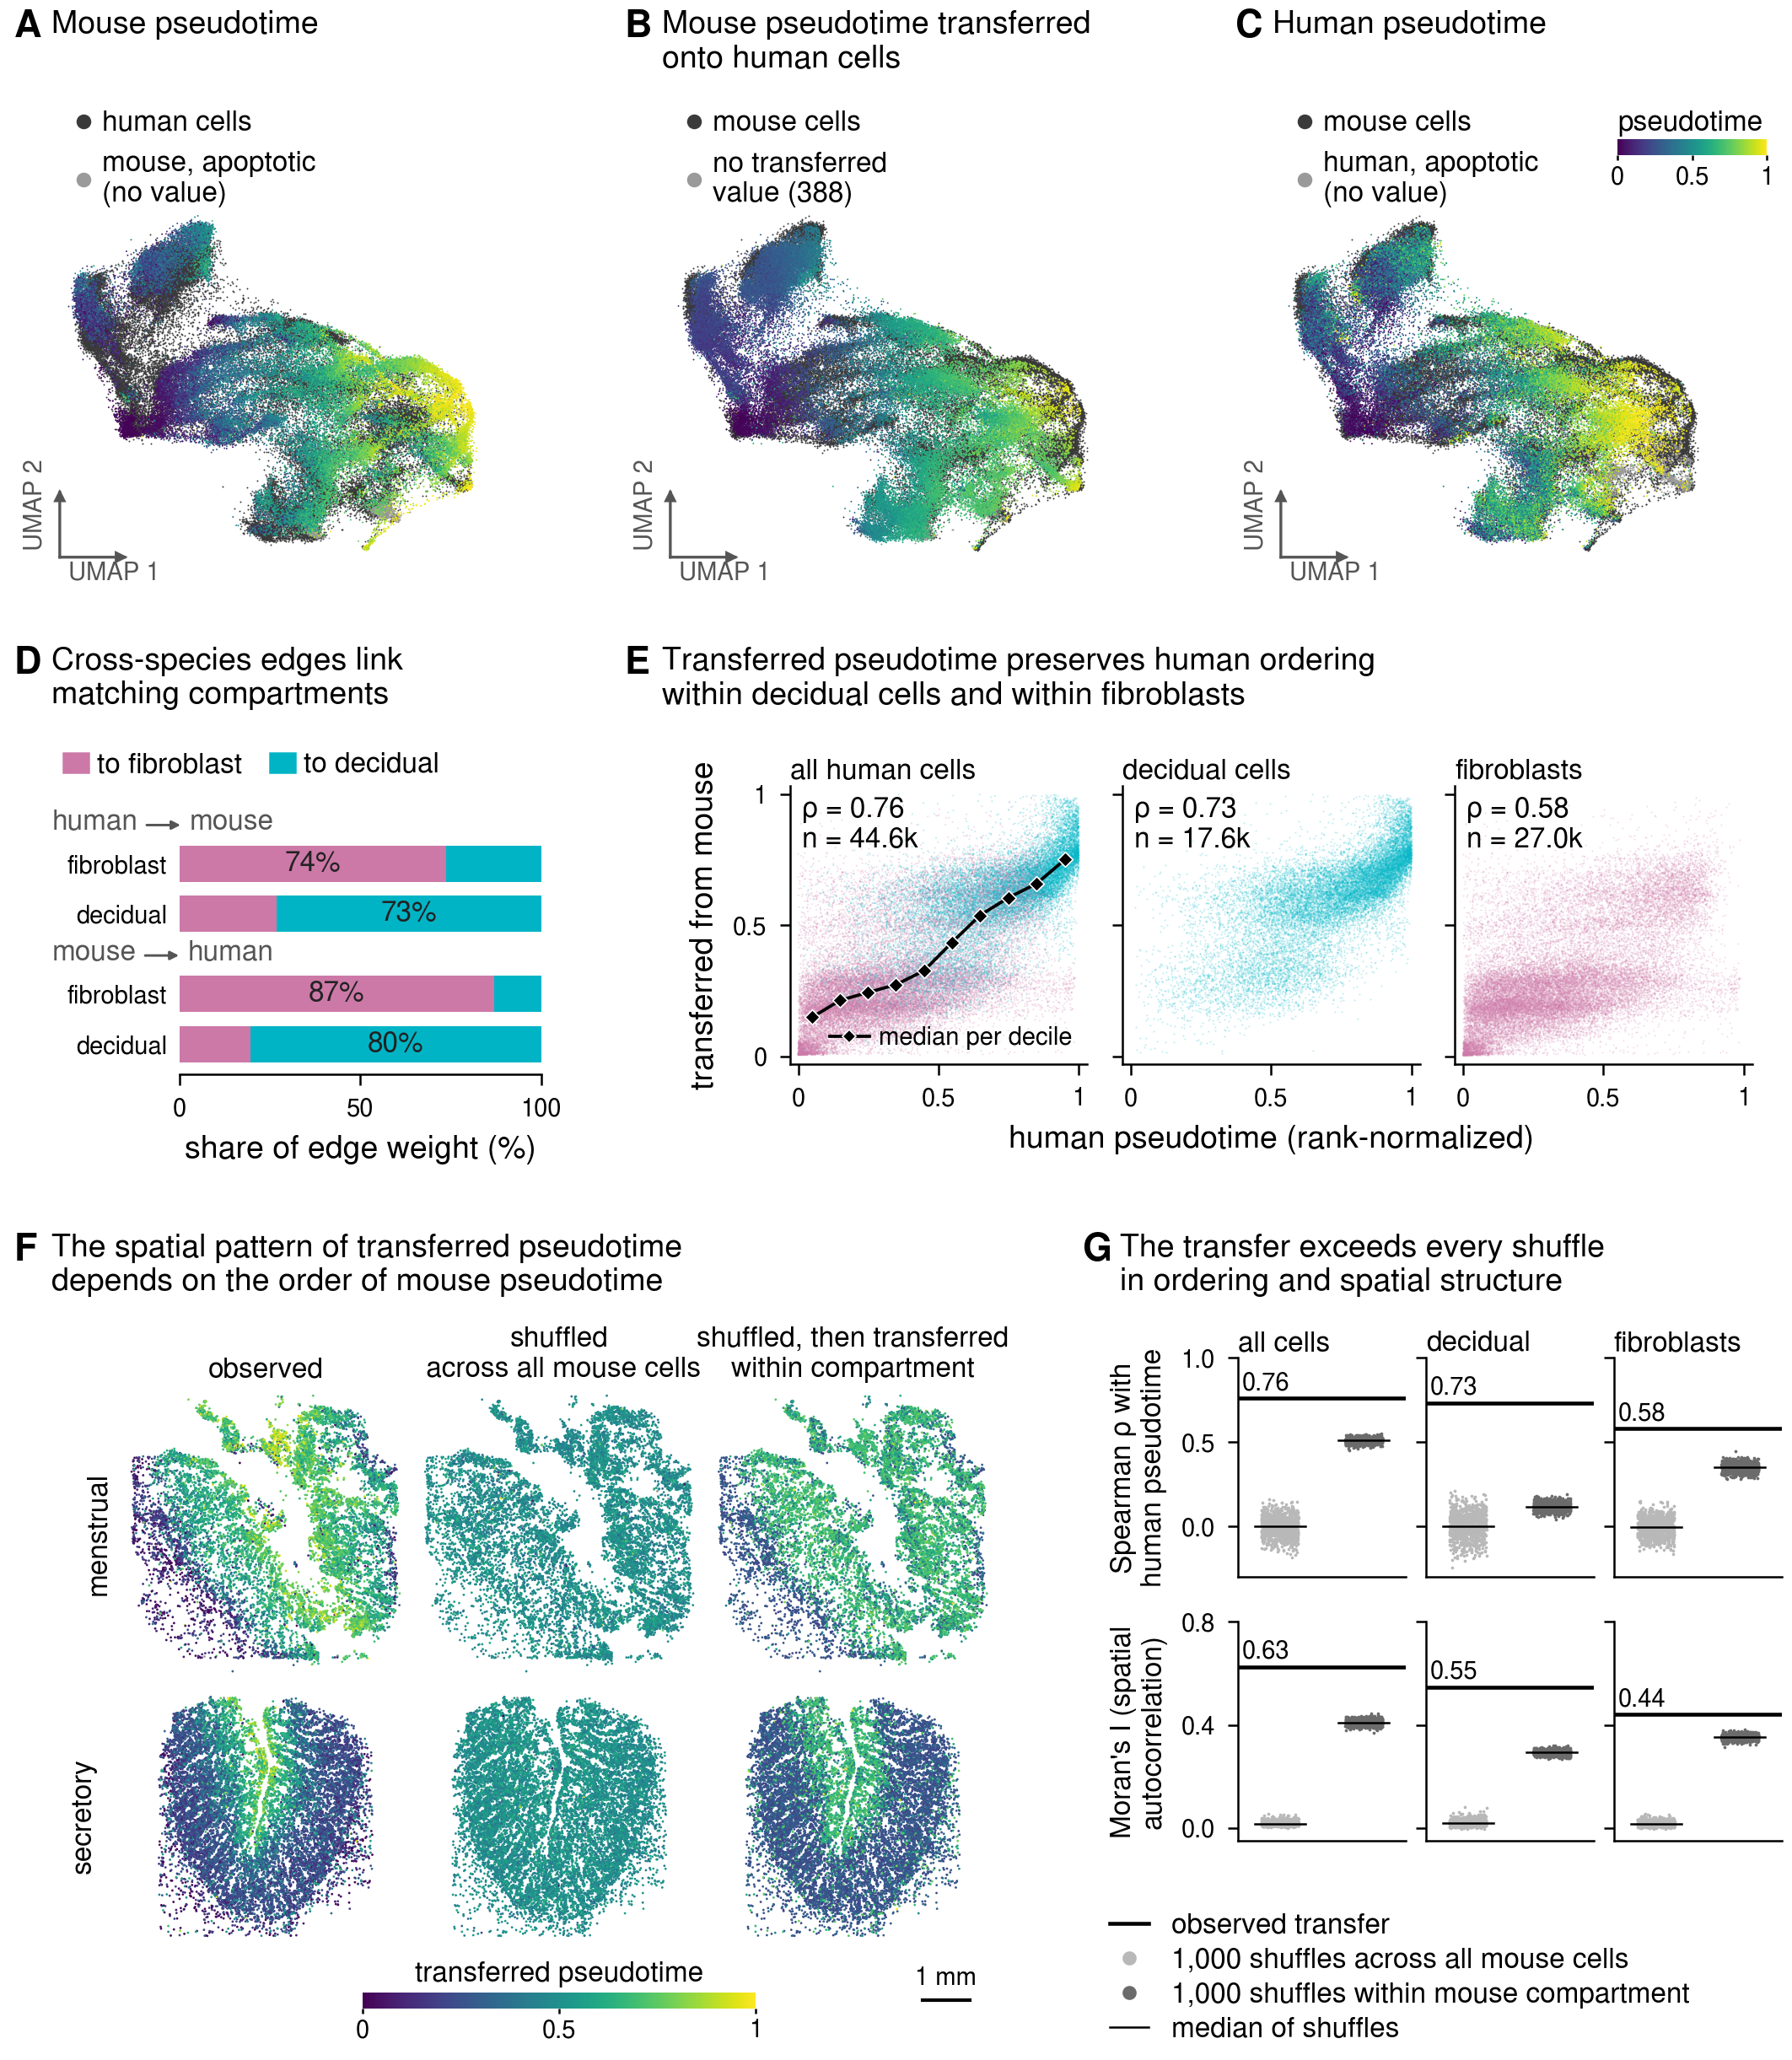

In [5]:
files = {letter: panel_files(letter) for letter in LETTERS}
missing = [str(p) for f in files.values() for p in f.values() if not p.exists()]
assert not missing, f"panel files missing: {missing}"
records = {letter: json.loads(f["provenance"].read_text()) for letter, f in files.items()}

# One font across the figure: a panel drawn with another font would not match its neighbors.
fonts = {letter: record.get("font", "") for letter, record in records.items()}
assert len(set(fonts.values())) == 1, f"panels were drawn with different fonts: {fonts}"
letter_font = bold_face(fonts["a"])
print(f"panel font {fonts['a']!r}; letters drawn with {letter_font}")

width_px, height_px = compose_png("png", outputs["png"], DPI, letter_font)
compose_png("png_600dpi", outputs["png_600dpi"], 600, letter_font)
compose_svg(outputs["svg"])
print(f"wrote {[p.name for p in outputs.values()]}: {width_px} x {height_px} px = "
      f"{width_px / (DPI / 25.4):.0f} x {height_px / (DPI / 25.4):.0f} mm")
display(ShowImage(filename=str(outputs["png"]), width=900))

## Provenance

In [6]:
sources = {}
for record in records.values():
    for entry in record.get("inputs", []):
        sources[entry["path"]] = entry
record = {
    "figure": "S32", "written": datetime.datetime.now().isoformat(timespec="seconds"), "host": platform.node(),
    "notebook": "figures/S32_samap_supp.ipynb",
    "objects": {name: {"path": str(path), "sha256": sha256(path)} for name, path in OBJECTS.items()},
    "shuffles": json.loads((TABLES / "ptnull" / "null_summary.json").read_text()),
    "parameters": {"OUT": str(OUT), "X_COLUMN": X_COLUMN, "Y_COLUMN": Y_COLUMN, "DATE": DATE,
                   "LETTER_FONT": LETTER_FONT},
    "panels": {letter: {"files": {k: str(p) for k, p in f.items()},
                        "sha256": {k: sha256(p) for k, p in f.items() if k != "provenance"},
                        **{k: records[letter].get(k) for k in ("notebook", "written", "font")}}
               for letter, f in files.items()},
    "sources": sorted(sources.values(), key=lambda e: e["path"]),
    "outputs": {k: {"path": str(p), "sha256": sha256(p)} for k, p in outputs.items()},
    "size_px": [width_px, height_px],
    "size_mm": [round(width_px / (DPI / 25.4), 1), round(height_px / (DPI / 25.4), 1)],
    "layout": {"width_mm": WIDTH_MM, "ncol": NCOL, "gutter_mm": GUTTER_MM, "row_heights_mm": ROW_HEIGHTS_MM,
               "panels": PANEL_SPECS},
    "letter_font": list(letter_font),
}
for key in ("spearman_rho", "permutation_observed", "permutation_replicates", "spatial_nuclei_drawn"):
    for letter in ("e", "f", "g"):
        if key in records[letter]:
            record[key] = records[letter][key]
sidecar.write_text(json.dumps(record, indent=1))
print(f"wrote {sidecar.name}")

wrote S32_samap_20261113.provenance.json
